# Puncta morphology histograms

Reads ONLY the two CSVs produced by `scripts/analysis/puncta_morphology.py`:

- the per-punctum CSV (one row per detected punctum, pre + post)
- the `*_images.csv` per-(file, role) summary (used to rebuild density)

No image-processing imports (no numpy array reloading of `.npy`, no
`skimage`) -- everything below is computed from the CSVs alone, so this
notebook can run on a laptop with just `pandas` / `numpy` / `matplotlib` /
`scipy`.

In [ ]:
import re
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

plt.rcParams["figure.dpi"] = 110

In [2]:
# --- Config: point these at the output of scripts/analysis/puncta_morphology.py ---
# (the paths below are this repo's documented convention: --output_csv outs/puncta_morphology.csv)
CSV_PATH = Path("../../outs/puncta_morphology.csv")
IMAGES_CSV_PATH = Path("../../outs/puncta_morphology_images.csv")
FIGURES_DIR = Path("figures")

N_BINS = 40
METRICS = ["radius_um", "a_um", "b_um", "eccentricity"]

In [3]:
df = pd.read_csv(CSV_PATH, sep=";")
images_df = pd.read_csv(IMAGES_CSV_PATH, sep=";")
print(f"{len(df)} puncta rows, {len(images_df)} file x role rows")
df.head()

6054 puncta rows, 6 file x role rows


,file_name,group_name,role,channel_index,dendrite_channel_index,x,y,radius_um,a_um,b_um,eccentricity,theta_deg,intensity,sigma_log,dendrite_area_um2,px_size_um,near_dilate_px
0,2_3_PSY_8_Multichannel Z-Stack_20251030_63.npy,Psilocybin,pre,0,2,531.277387,1370.703796,0.438319,0.469281,0.409400,0.488797,-50.793680,0.935333,2.2,8156.332064,0.106854,4
1,2_3_PSY_8_Multichannel Z-Stack_20251030_63.npy,Psilocybin,pre,0,2,982.217629,1152.349836,0.586812,0.689909,0.499122,0.690366,-26.109185,0.910667,3.0,8156.332064,0.106854,4
2,2_3_PSY_8_Multichannel Z-Stack_20251030_63.npy,Psilocybin,pre,0,2,1234.252764,1744.456106,0.503378,0.544875,0.465042,0.521119,-18.056423,0.959333,2.2,8156.332064,0.106854,4
3,2_3_PSY_8_Multichannel Z-Stack_20251030_63.npy,Psilocybin,pre,0,2,1369.722209,1642.348828,0.580513,0.718367,0.469113,0.757335,-130.971354,0.913333,2.6,8156.332064,0.106854,4
4,2_3_PSY_8_Multichannel Z-Stack_20251030_63.npy,Psilocybin,pre,0,2,928.124383,283.408476,0.634329,0.819558,0.490964,0.800705,-133.434226,0.940000,2.6,8156.332064,0.106854,4


## Density rebuild from the images CSV

Density (puncta / um^2) is NOT a column in the per-punctum CSV -- it only
makes sense per (file, role), so it is rebuilt here from `images_df`
(`n_puncta / dendrite_area_um2`), matching the density shown by
`analyse_image` in step 2 / the CLI check in step 3.

In [4]:
density_df = images_df.copy()
density_df["density_um2"] = density_df["n_puncta"] / density_df["dendrite_area_um2"]
density_df.groupby("role")["density_um2"].describe()

,count,mean,std,min,25%,50%,75%,max
role,,,,,,,,
post,3.0,0.070055,0.034468,0.031209,0.056593,0.081977,0.089479,0.096980
pre,3.0,0.166499,0.031395,0.131079,0.154301,0.177522,0.184208,0.190895


## Subset filter

One reusable substring filter (`time_filter`) is used everywhere below --
no subsetting logic is duplicated in the plotting cells. It matches
case-insensitively against `group_name` by default (e.g. `"24h"` vs.
`"1h pulse"`, following the qualifiers appended by
`configs/clustering/group_patterns.json`'s `time_points` / `washouts`
rules), but any column can be passed.

Edit `SUBSETS` below to add / remove panels -- that is the *only* place
subset substrings are written down.

In [5]:
def time_filter(frame: pd.DataFrame, substring: str | None, column: str = "group_name") -> pd.DataFrame:
    """Rows of `frame` whose `column` contains `substring` (case-insensitive).

    `substring=None` (or `""`) returns `frame` unchanged -- this is the
    "All" subset.
    """
    if not substring:
        return frame
    pattern = re.escape(substring)
    return frame[frame[column].astype(str).str.contains(pattern, case=False, regex=True, na=False)]


# Label -> substring to match in `group_name`. Add/remove entries freely;
# this dict is the only place subset substrings are hard-coded.
SUBSETS: dict[str, str | None] = {
    "All": None,
    "24h": "24h",
    "48h": "48h",
    "72h": "72h",
    "1h pulse": "1h pulse",
}

## Bin edges (computed once from the full CSV)

Every subset panel for a given metric reuses the same bin edges (computed
from the full, unfiltered data) so histograms stay visually comparable
across subsets.

In [6]:
bin_edges: dict[str, np.ndarray] = {}
for metric in METRICS:
    vals = df[metric].to_numpy()
    bin_edges[metric] = np.linspace(vals.min(), vals.max(), N_BINS + 1)

density_vals = density_df["density_um2"].to_numpy()
bin_edges["density_um2"] = np.linspace(density_vals.min(), density_vals.max(), N_BINS + 1)

{k: (v[0], v[-1]) for k, v in bin_edges.items()}

{'radius_um': (np.float64(0.3979779765499103), np.float64(1.3146625298075456)),
 'a_um': (np.float64(0.4356483028820296), np.float64(1.838424994680739)),
 'b_um': (np.float64(0.2962840302313969), np.float64(1.1362847361932984)),
 'eccentricity': (np.float64(0.0753581470341974),
  np.float64(0.9499696027427752)),
 'density_um2': (np.float64(0.03120925926655517),
  np.float64(0.1908946310501387))}

## Plotting helper

One panel = one metric, pre (red) + post (green) overlaid as histogram +
`scipy.stats.gaussian_kde` smooth curve, with a text box reporting
n / min / p5 / median / p95 / max per role.

In [7]:
ROLE_COLORS = {"pre": "tab:red", "post": "tab:green"}


def plot_metric_hist(ax, values_by_role: dict[str, np.ndarray], edges: np.ndarray,
                      title: str, xlabel: str) -> None:
    stat_lines = []
    for role, color in ROLE_COLORS.items():
        values = values_by_role.get(role, np.empty(0))
        if values.size == 0:
            continue
        ax.hist(values, bins=edges, density=True, alpha=0.35, color=color, label=role)
        if values.size > 1 and np.ptp(values) > 0:
            kde = stats.gaussian_kde(values)
            xs = np.linspace(edges[0], edges[-1], 200)
            ax.plot(xs, kde(xs), color=color, linewidth=1.5)
        p5, p50, p95 = np.percentile(values, [5, 50, 95])
        stat_lines.append(
            f"{role}: n={values.size} min={values.min():.3g} p5={p5:.3g} "
            f"median={p50:.3g} p95={p95:.3g} max={values.max():.3g}"
        )

    ax.set_title(title)
    ax.set_xlabel(xlabel)
    ax.set_ylabel("density")
    if stat_lines:
        ax.legend(fontsize=7, loc="upper left")
        ax.text(
            0.98, 0.98, "\n".join(stat_lines), transform=ax.transAxes,
            fontsize=6.5, va="top", ha="right",
            bbox=dict(boxstyle="round", fc="white", ec="0.7", alpha=0.85),
        )
    else:
        ax.text(0.5, 0.5, "no data", transform=ax.transAxes, ha="center", va="center")

## Figures (one per subset) + summary table

Saves every subset figure as PNG + SVG into `FIGURES_DIR`. Subsets with no
matching rows still render (empty panels say "no data") instead of
crashing -- useful when a subset's substring does not occur in the
current dataset.

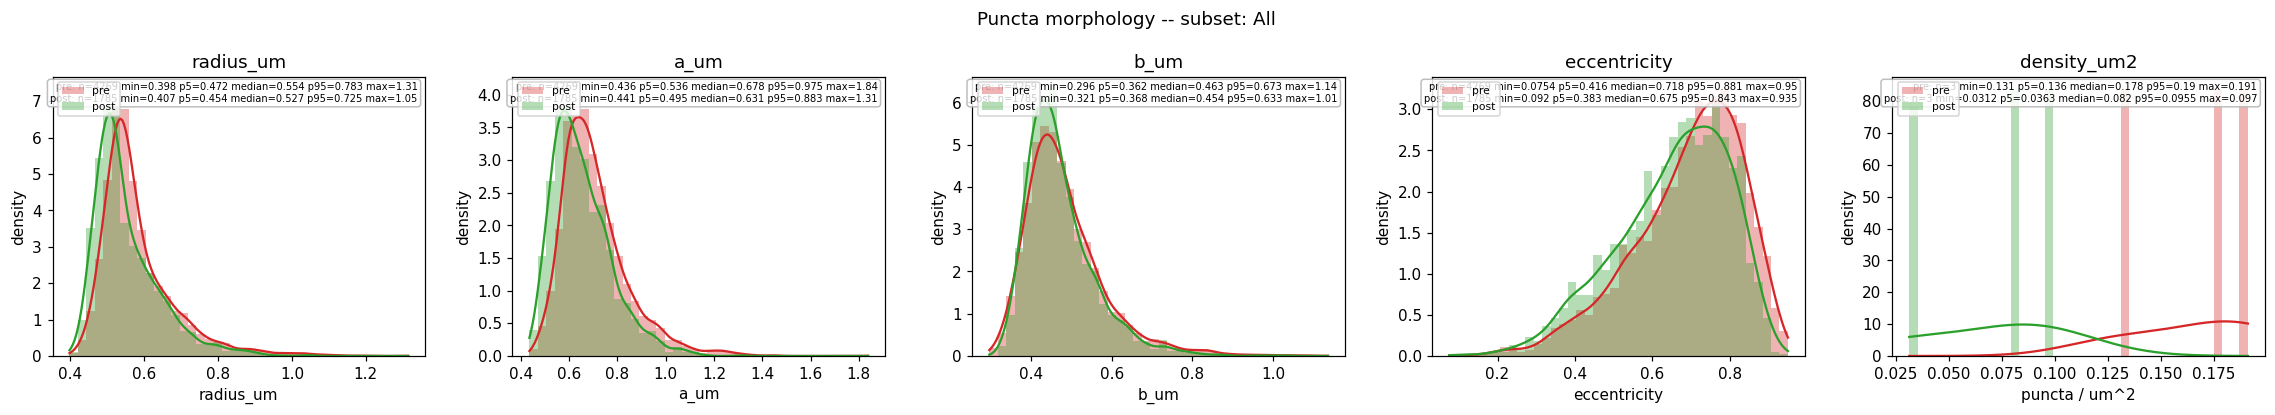

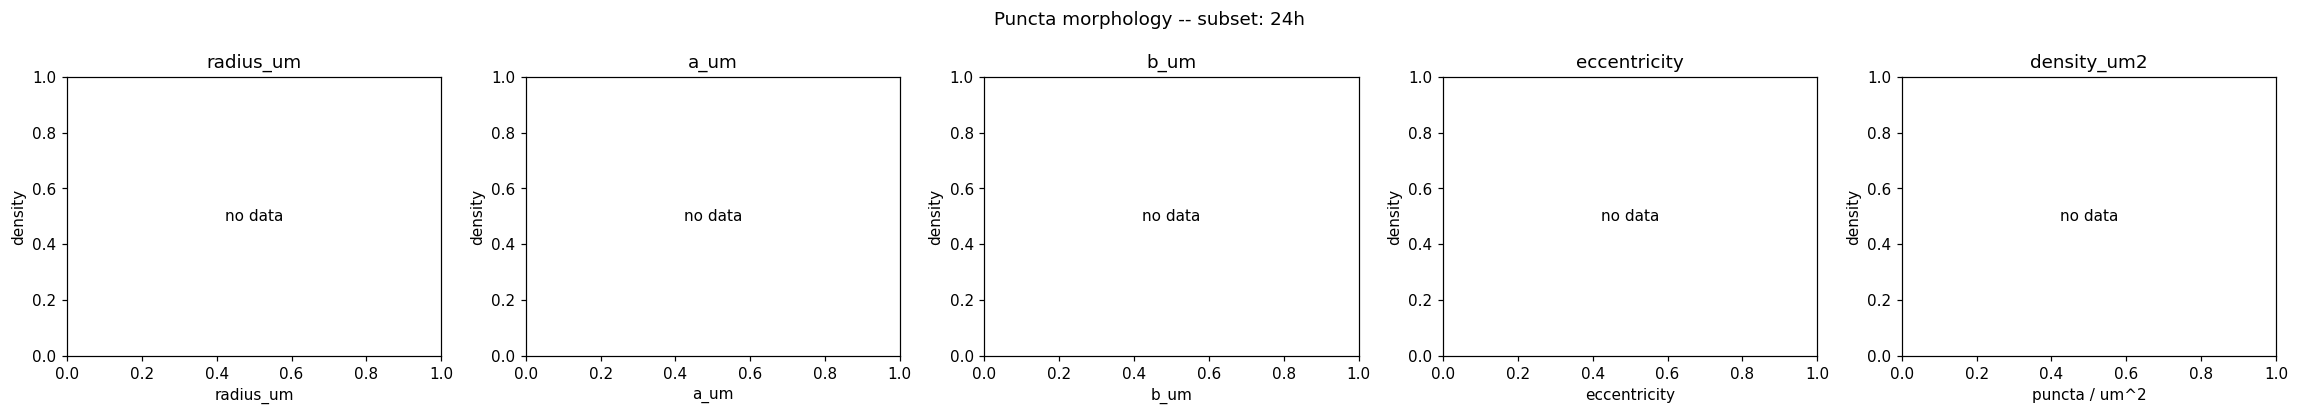

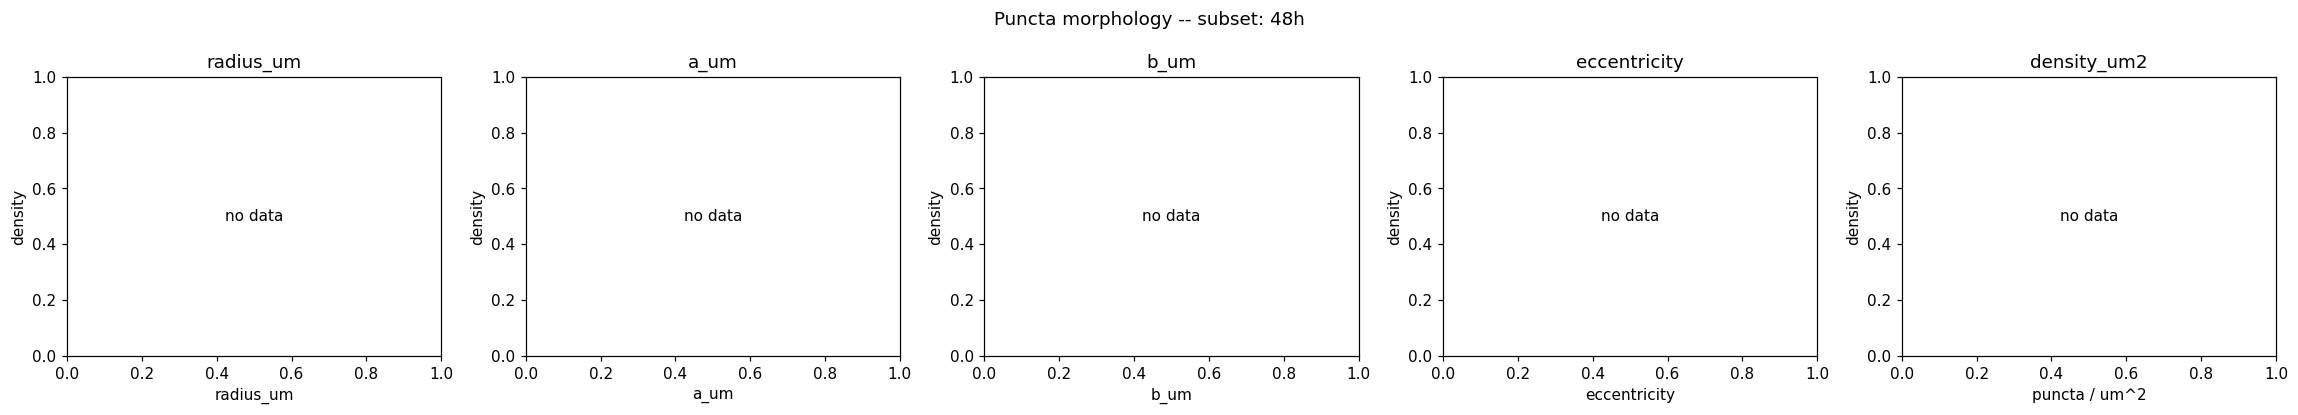

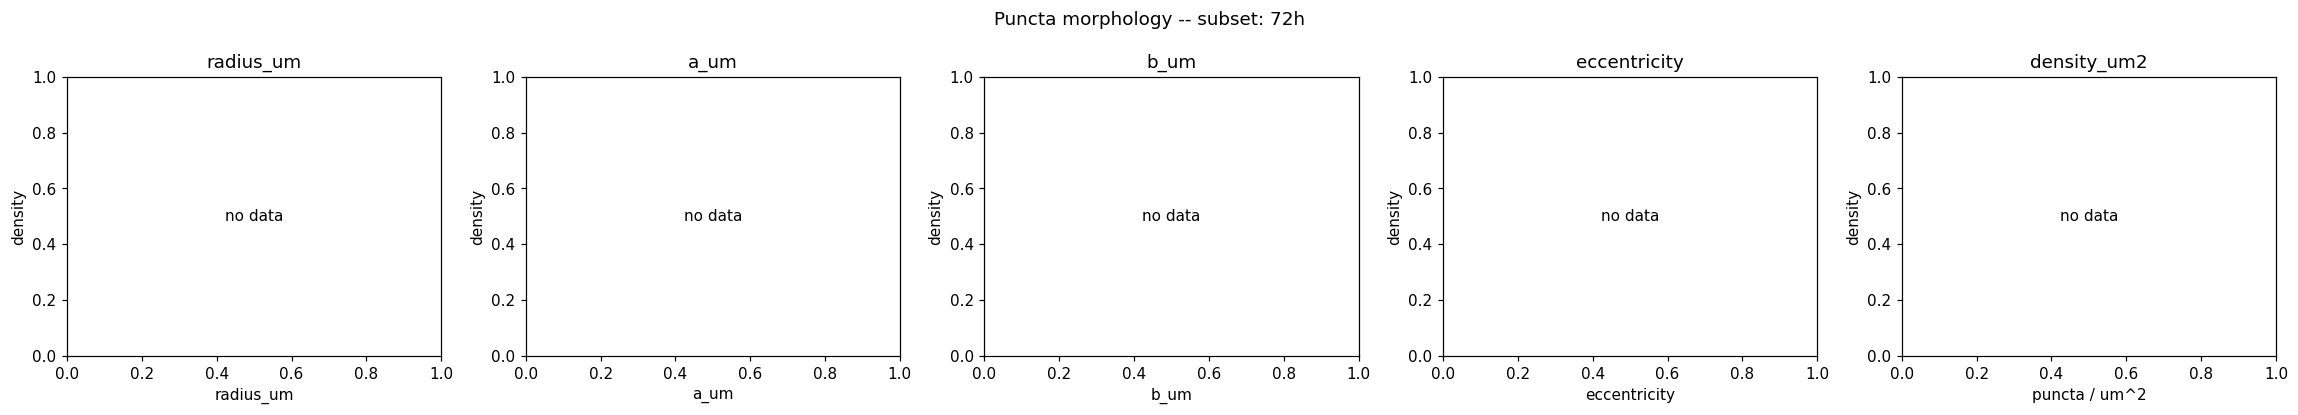

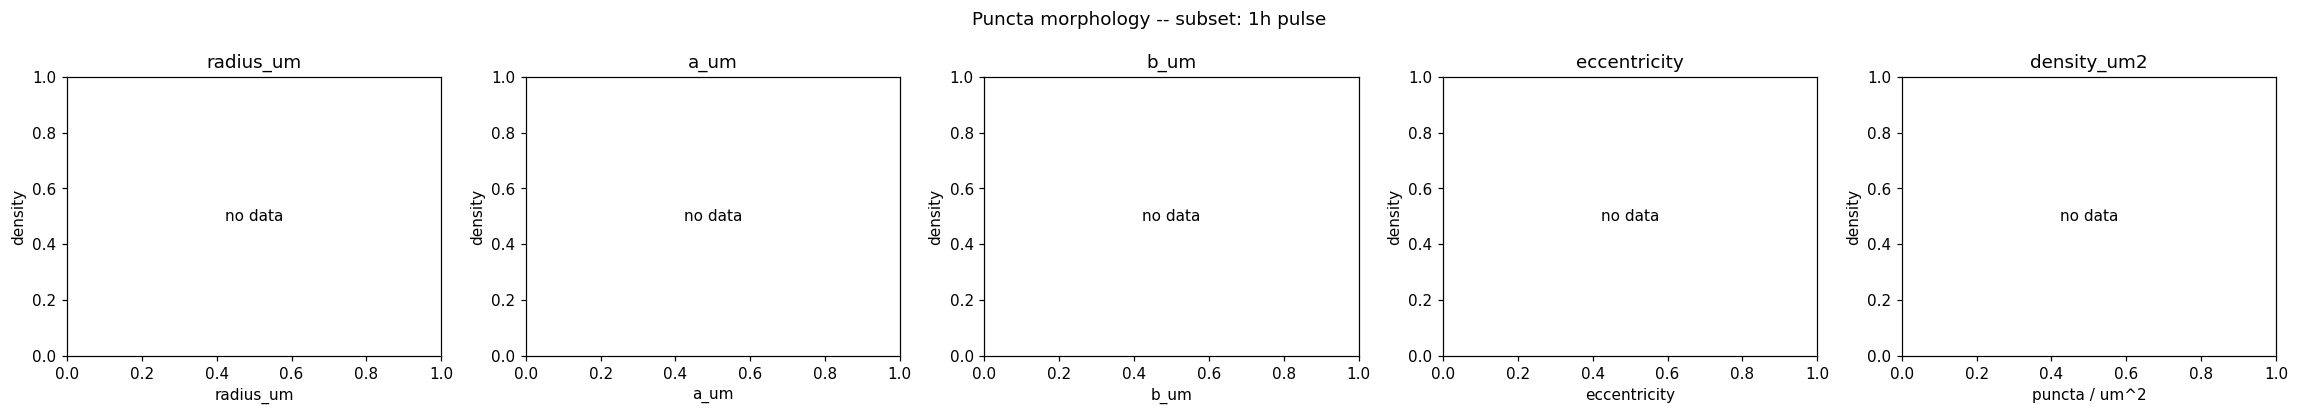

,subset,role,n_puncta,n_images,median_radius_um,median_eccentricity,median_density_um2
0,All,pre,4269,3,0.554001,0.717654,0.177522
1,All,post,1785,3,0.526984,0.675284,0.081977
2,24h,pre,0,0,NaN,NaN,NaN
3,24h,post,0,0,NaN,NaN,NaN
4,48h,pre,0,0,NaN,NaN,NaN
5,48h,post,0,0,NaN,NaN,NaN
6,72h,pre,0,0,NaN,NaN,NaN
7,72h,post,0,0,NaN,NaN,NaN
8,1h pulse,pre,0,0,NaN,NaN,NaN
9,1h pulse,post,0,0,NaN,NaN,NaN


In [8]:
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
PANELS = METRICS + ["density_um2"]
summary_rows = []

for subset_label, substring in SUBSETS.items():
    sub_df = time_filter(df, substring)
    sub_density = time_filter(density_df, substring)

    fig, axes = plt.subplots(1, len(PANELS), figsize=(4.2 * len(PANELS), 3.8))
    for ax, metric in zip(axes, PANELS):
        if metric == "density_um2":
            values_by_role = {
                role: sub_density.loc[sub_density["role"] == role, "density_um2"].to_numpy()
                for role in ROLE_COLORS
            }
            xlabel = "puncta / um^2"
        else:
            values_by_role = {
                role: sub_df.loc[sub_df["role"] == role, metric].to_numpy()
                for role in ROLE_COLORS
            }
            xlabel = metric
        plot_metric_hist(ax, values_by_role, bin_edges[metric], metric, xlabel)

    fig.suptitle(f"Puncta morphology -- subset: {subset_label}")
    fig.tight_layout()
    safe_label = re.sub(r"\W+", "_", subset_label).strip("_")
    fig.savefig(FIGURES_DIR / f"puncta_{safe_label}.png", dpi=150)
    fig.savefig(FIGURES_DIR / f"puncta_{safe_label}.svg")
    plt.show()

    for role in ROLE_COLORS:
        role_df = sub_df[sub_df["role"] == role]
        role_density = sub_density[sub_density["role"] == role]
        summary_rows.append(dict(
            subset=subset_label,
            role=role,
            n_puncta=len(role_df),
            n_images=role_density["file_name"].nunique(),
            median_radius_um=role_df["radius_um"].median() if len(role_df) else np.nan,
            median_eccentricity=role_df["eccentricity"].median() if len(role_df) else np.nan,
            median_density_um2=role_density["density_um2"].median() if len(role_density) else np.nan,
        ))

summary_table = pd.DataFrame(summary_rows)
summary_table